In [1]:
# Prerequisites
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 200
plt.rcParams["figure.figsize"] = (12, 5)

## ToDo:

- x find severall blob shaping functions
    - x mimic them
    - x understand them
    - x store source!
- x figure out which one works best for our purposes (-> Idea 3!!!)
- x ask someone else (Sina, Jakob)
- x implement as shape method
- o write tests
- o write tutorial

### Idea 1

Source: https://gamedev.stackexchange.com/questions/62613/need-ideas-for-an-algorithm-to-draw-irregular-blotchy-shapes

Draw the outlines around a central point using polar coordinates:
$$ r=1+w_1*sin(\theta+\theta_1)+w_2*sin(2\theta+\theta_2)+w_3*sin(3\theta+\theta_3) + ...$$ 

In [2]:
import numpy as np

def term(x, i, w, theta):
    return w*np.sin(i*x + theta)

def funny_curve(x, I):
    res = 1
    for i in range(1, I+1):
        w = np.random.uniform(0.1, 1.0)
        theta = np.random.uniform(0, 2*np.pi)
        #print(f"i: {i}, w: {w}, theta: {theta}")
        res += term(x, i, w, theta)
    return res

funny_curve(1, 1)

np.float64(0.7892676590718294)

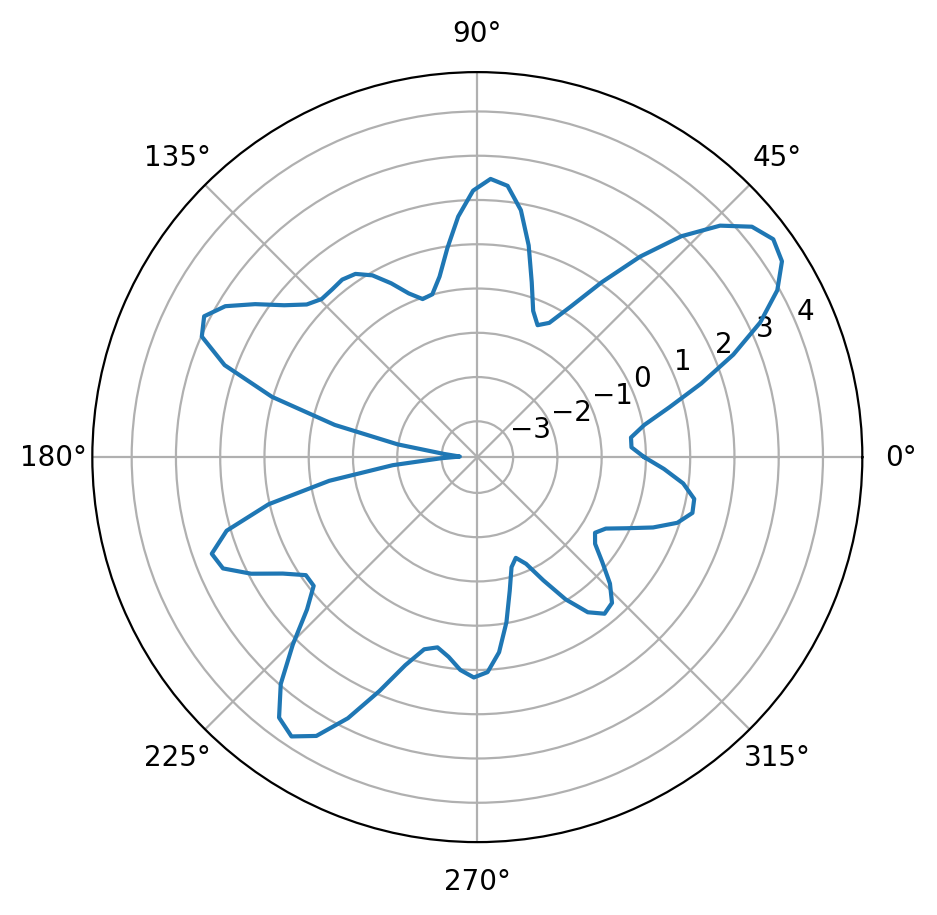

In [3]:
# plot in polar coordinates
import matplotlib.pyplot as plt
import numpy as np

theta = np.linspace(0, 2*np.pi, 100)
r = funny_curve(theta, 10)

plt.polar(theta, r)
plt.show()

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def term(x, i, w, theta):
    return w * np.sin(i * x + theta)

def funny_curve(angle, I, w_params, theta_params):
    res = np.ones_like(angle)
    for i in range(1, I + 1):
        res += term(angle, i, w_params[i - 1], theta_params[i - 1])
    return res

def make_shape(
    lats=np.linspace(-90, 90, 180),   # latitude grid
    lons=np.linspace(-180, 180, 360), # longitude grid
    max_radius=10.0,                  # angular radius in degrees
    center_lat=0.0,
    center_lon=0.0,
    random_seed=None,
    I=5,                              # number of sine terms
):
    if random_seed is not None:
        np.random.seed(random_seed)

    # Shape parameters
    w_params = []#np.random.uniform(min_radius, max_radius, size=I)
    for i in range(1,I+1):
        w = np.random.uniform(0, max_radius/(i))
        w_params.append(w)
    #print(f"w_params: {w_params}")
    theta_params = np.random.uniform(0, 2 * np.pi, size=I)
    #print(f"theta_params: {theta_params}")

    # Build lat/lon mesh
    Lon, Lat = np.meshgrid(lons, lats)

    # Compute offset from center (in degrees)
    dlat = Lat - center_lat
    dlon = Lon - center_lon

    # Adjust longitude difference for wrap-around
    dlon = (dlon + 180) % 360 - 180

    # Equirectangular approximation for distance in degrees
    # Account for longitude scaling with cos(lat_center)
    x = dlon * np.cos(np.radians(center_lat))
    y = dlat
    R = np.sqrt(x**2 + y**2)  # distance in degrees
    Theta = np.arctan2(y, x)  # angle in radians
    Theta[Theta < 0] += 2 * np.pi

    # Evaluate curve at each angle
    boundary_R = funny_curve(Theta, I, w_params, theta_params)

    # Scale boundary_R so that the maximum possible radius matches max_radius
    scale_factor = max_radius / np.max(boundary_R)
    boundary_R += scale_factor

    # Mask: inside if R <= boundary radius at that angle
    mask = (R <= boundary_R)

    return mask


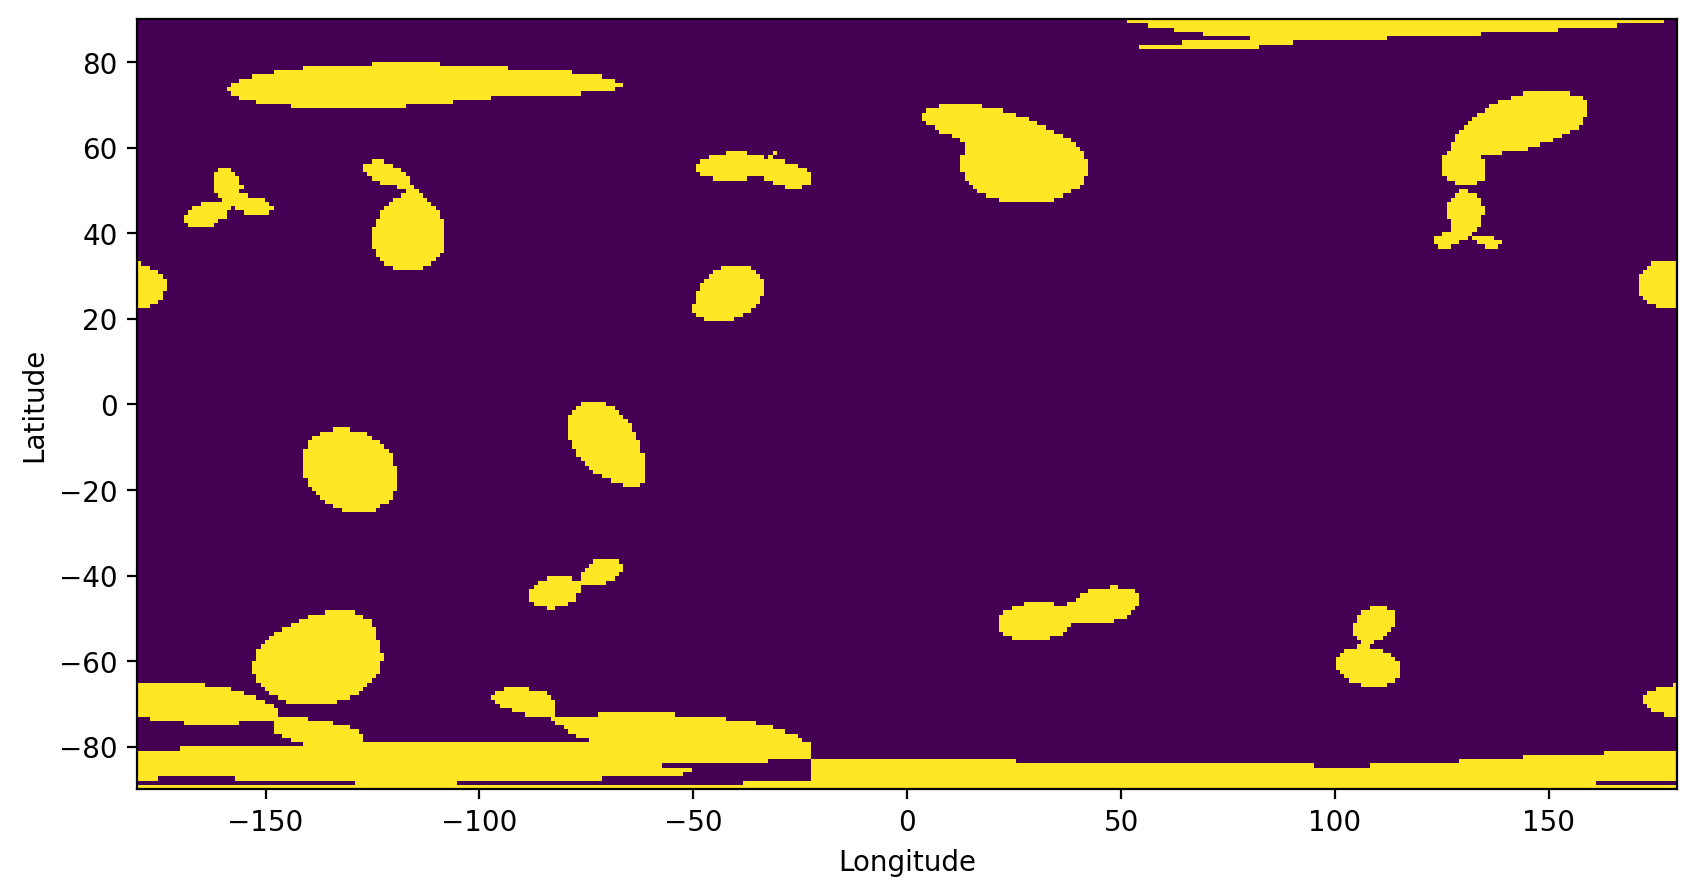

In [5]:
# --- Example usage ---
lat_extend = 90
lon_extend = 180
samples = 20

mask_tot = np.zeros((2*lat_extend + 1, 2*lon_extend + 1), dtype=bool)
for _ in range(samples):
    center_lat = np.random.uniform(-lat_extend, lat_extend)
    center_lon = np.random.uniform(-lon_extend, lon_extend)

    mask = make_shape(
        lats=np.linspace(-lat_extend, lat_extend, 2*lat_extend + 1),
        lons=np.linspace(-lon_extend, lon_extend, 2*lon_extend + 1),
        max_radius=lon_extend/10,  # Use lon_extend as max_radius
        center_lat=center_lat,
        center_lon=center_lon,
        I=3,
        random_seed=None,  # Set to None for random parameters
    )

    mask_tot |= mask

plt.figure(figsize=(12, 5))
plt.imshow(mask_tot, extent=(-lon_extend, lon_extend, -lat_extend, lat_extend),
            origin='lower', cmap='viridis')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

## Idea 2

Source: https://stackoverflow.com/questions/3587704/good-way-to-procedurally-generate-a-blob-graphic-in-2d

In [6]:
import cmath, math
from math import atan2

def convexHull(pts):    #Graham's scan.
    xleftmost, yleftmost = min(pts)
    by_theta = [(atan2(x-xleftmost, y-yleftmost), x, y) for x, y in pts]
    by_theta.sort()
    as_complex = [complex(x, y) for _, x, y in by_theta]
    chull = as_complex[:2]
    for pt in as_complex[2:]:
        #Perp product.
        while ((pt - chull[-1]).conjugate() * (chull[-1] - chull[-2])).imag < 0:
            chull.pop()             # remove points that would make a right turn
        chull.append(pt)
    return [(pt.real, pt.imag) for pt in chull]

def dft(xs, inverse=False):
    N = len(xs)
    sign = 1 if inverse else -1
    out = []
    for k in range(N):
        s = 0
        for n, x in enumerate(xs):
            s += x * cmath.exp(-2j * math.pi * n * k / N) if not inverse else x * cmath.exp(2j * math.pi * n * k / N)
        out.append(s)
    if inverse:
        return [z / N for z in out]
    return out


def interpolateSmoothly(xs, N):
    """For each point, add N points."""
    fs = dft(xs)
    half = (len(xs) + 1) // 2
    fs2 = fs[:half] + [0]*(len(fs)*N) + fs[half:]
    return [x.real / len(xs) for x in dft(fs2)[::-1]]

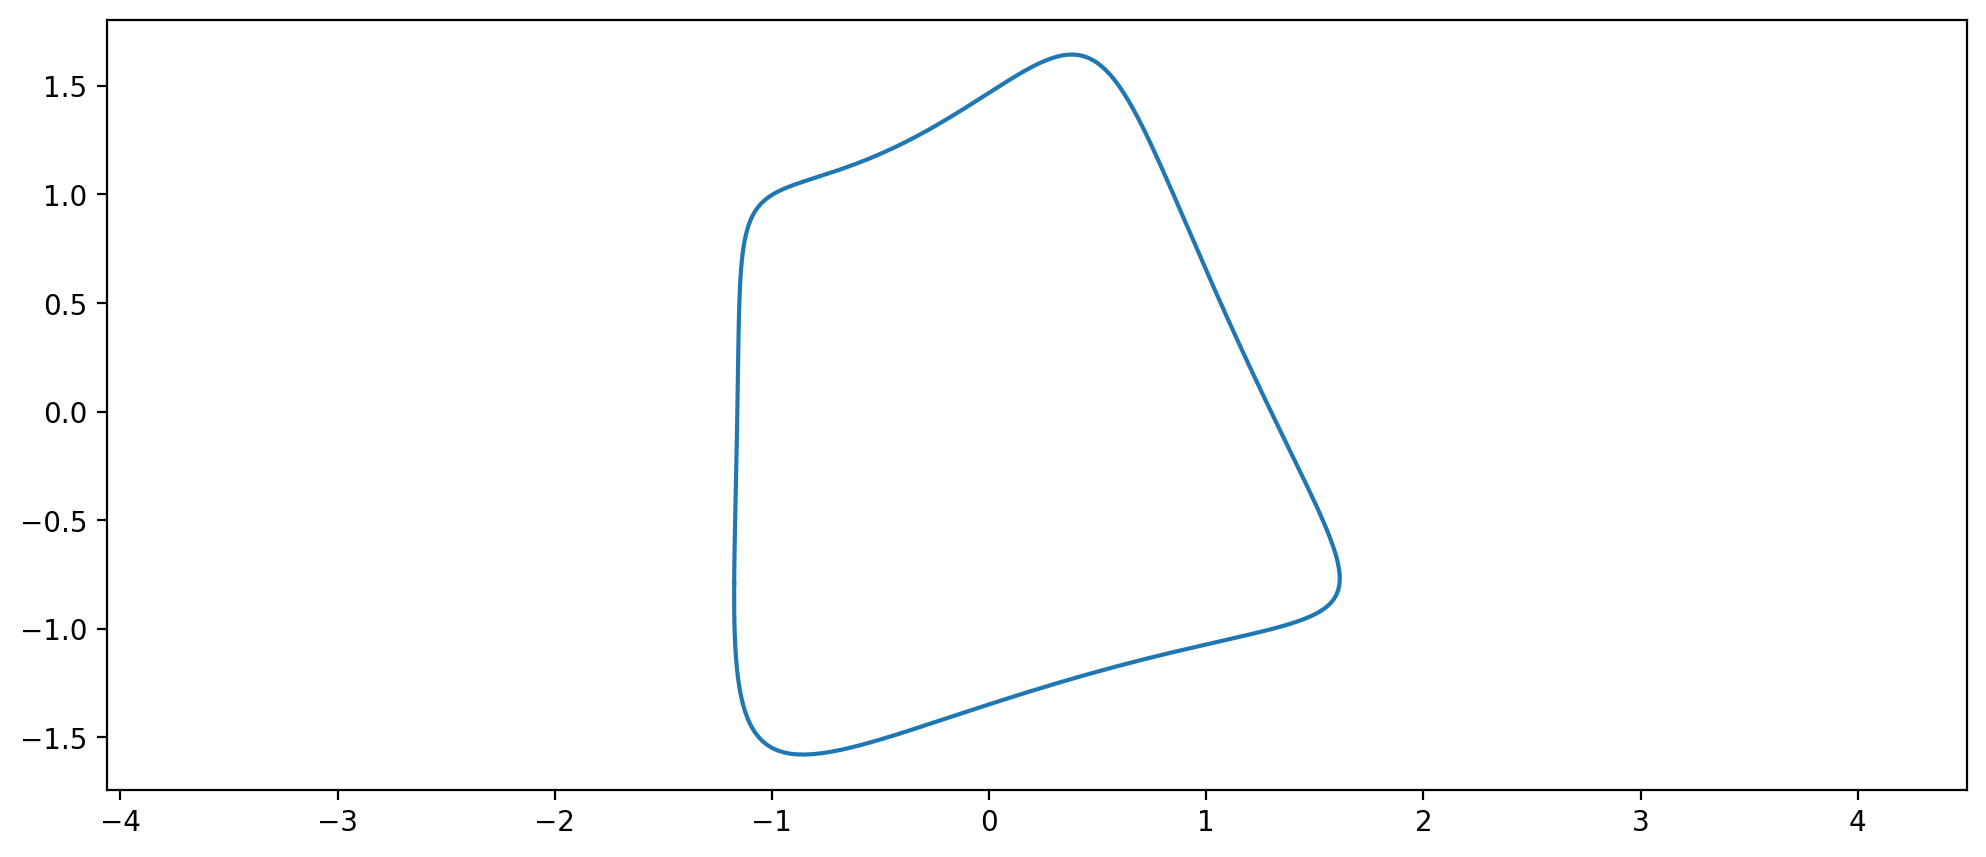

In [7]:
import matplotlib.pyplot as plt
import numpy as np

I = 10

pts = [(np.random.uniform() + 0.8) * np.exp(2j*np.pi*i/I) for i in range(I)]
pts = convexHull([(pt.real, pt.imag ) for pt in pts])
xs, ys = [interpolateSmoothly(zs, 30) for zs in zip(*pts[:])]

xs.append(xs[0])
ys.append(ys[0])

plt.plot(xs, ys, linestyle='-')
plt.axis('equal')
plt.show()  

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path
import cmath

def make_shape(
    lats=np.linspace(-90, 90, 181),   # latitude grid
    lons=np.linspace(-180, 180, 361), # longitude grid
    center_lat=0.0,
    center_lon=0.0,
    radius=10.0,
    I=5,
    random_seed=None,
):
    if random_seed is not None:
        np.random.seed(random_seed)

    pi = np.pi  # more accurate π

    # Create random points in polar form, then get convex hull
    pts = [(np.random.random() * radius) * cmath.exp(2j * pi * i / I) for i in range(I)]
    pts = convexHull([(pt.real, pt.imag) for pt in pts])
    
    # Smooth/interpolate polygon boundary
    xs, ys = [interpolateSmoothly(zs, 30) for zs in zip(*pts)]
    
    # Shift to desired center in lat/lon space
    xs = np.array(xs) + center_lon
    ys = np.array(ys) + center_lat

    # Create Path in geographic coordinates (lon, lat)
    polygon = Path(np.column_stack((xs, ys)))

    # Create meshgrid of lon/lat points
    extended_lons = np.concatenate([lons - 360, lons, lons + 360])
    lat_grid, lon_grid = np.meshgrid(lats, extended_lons, indexing="ij")
    points = np.column_stack((lon_grid.ravel(), lat_grid.ravel()))

    # Test which points are inside polygon
    mask = polygon.contains_points(points)
    mask = mask.reshape(lon_grid.shape)

    # add up contributions from periodic longitudes, shape_contribution is of shape (lat_size, lon_size)
    # - split shape_mask into three parts, one for each longitude section
    mask = mask.reshape(len(lats), 3, len(lons))
    # - transpose to have latitudes as first dimension
    mask = mask.transpose(1, 0, 2)
    # - if any of the three sections is True, then the point is part of the shape
    mask = np.any(mask, axis=0)

    return mask


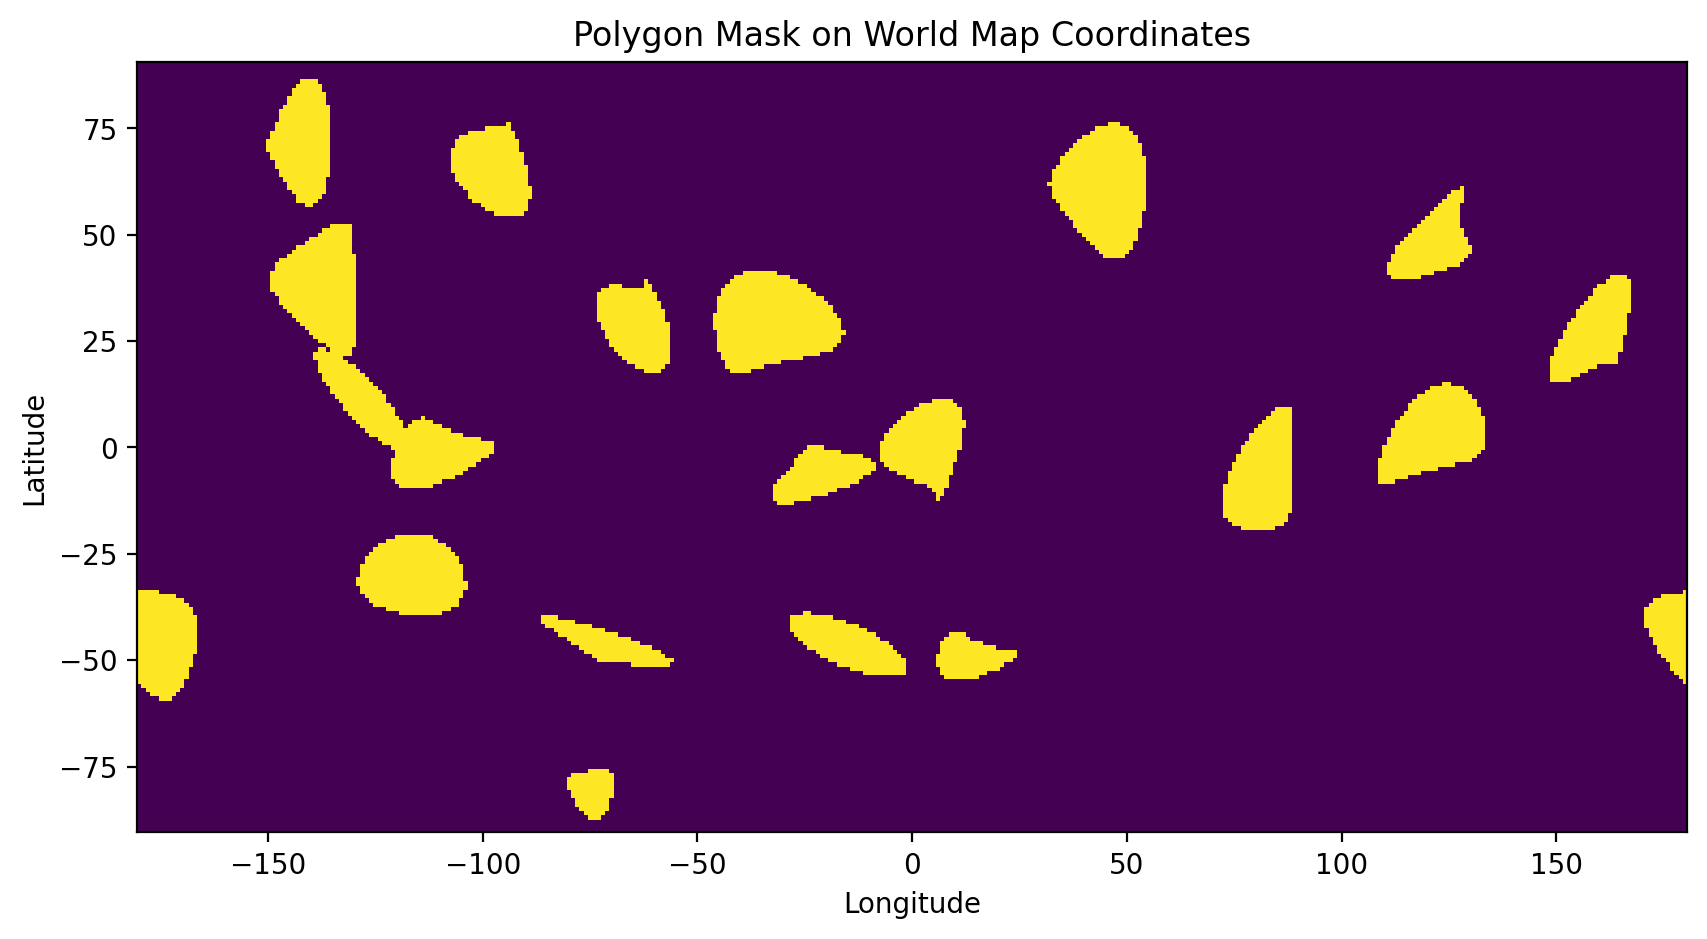

In [9]:

# Example usage
lat_extent = 90
lon_extent = 180
samples = 20

lats = np.linspace(-lat_extent, lat_extent, 2 * lat_extent + 1)
lons = np.linspace(-lon_extent, lon_extent, 2 * lon_extent + 1)

mask_tot = np.zeros((2*lat_extent + 1, 2*lon_extent + 1), dtype=bool)
for _ in range(samples):
    center_lat = np.random.uniform(-lat_extent, lat_extent)
    center_lon = np.random.uniform(-lon_extent, lon_extent)

    # Create a polygon mask
    mask = make_shape(
        lats=lats,
        lons=lons,
        center_lat=center_lat,
        center_lon=center_lon,
        radius=lon_extent / 10,  # Use lon_extent as radius
        I=5,
        #random_seed=8,
)
    mask_tot |= mask

# Plot on a world coordinate grid
plt.figure(figsize=(10, 5))
plt.pcolormesh(lons, lats, mask_tot, cmap='viridis', shading='auto')
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Polygon Mask on World Map Coordinates")
plt.show()

## Idea 3

Source: https://web.archive.org/web/20161018194403/https://www.niksula.hut.fi/%7Ehkankaan/Homepages/metaballs.html

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import label

def is_single_connected(mask, connectivity=1):
    """...

    """
    if not np.any(mask):
        return False  # No True cells at all

    # Select structure for connectivity
    if connectivity == 1:
        structure = np.array([[0,1,0],
                               [1,1,1],
                               [0,1,0]], dtype=bool)
    elif connectivity == 2:
        structure = np.ones((3,3), dtype=bool)
    else:
        raise ValueError("connectivity must be 1 or 2")
    
    # Label connected components in extended mask
    labeled, num_features = label(mask, structure=structure)

    if num_features == 1:
        return True
    # check if split at longitude
    else:
        lon_size = mask.shape[1]
        extended_mask = np.hstack([mask, mask])  # (lat, 2*lon)
        extended_mask = extended_mask[:, lon_size//2:3*lon_size//2]  # keep only the middle section

        # Label connected components in extended mask
        labeled, num_features = label(extended_mask, structure=structure)

        if num_features == 1:
            return True
        else:
            return False

class Ball:
    """Single metaball."""
    def __init__(self, lat, lon, size):
        self.lat = lat
        self.lon = lon
        self.size = size

class MetaballSystemGeo:
    """Metaball system in lat/lon space with longitude wrapping."""
    def __init__(self, balls, goo=2.0, threshold=0.0004):
        self.balls = balls
        self.goo = goo
        self.threshold = threshold

    def _distance(self, lat1, lon1, lat2, lon2):
        """Euclidean distance in lat/lon degrees, with lon wrapping."""
        # Wrap longitudes to [-180, 180]
        dlon = ((lon1 - lon2 + 180) % 360) - 180
        dlat = lat1 - lat2
        return np.sqrt(dlat**2 + dlon**2)

    def field_mask(self, lats, lons):
        """Compute boolean mask for the metaball field."""
        LAT, LON = np.meshgrid(lats, lons, indexing="ij")  # shape (lat_size, lon_size)
        field = np.zeros_like(LAT, dtype=float)

        for ball in self.balls:
            dist = self._distance(LAT, LON, ball.lat, ball.lon)
            # avoid division by zero
            dist[dist == 0] = 1e-12
            field += ball.size / (dist**self.goo)

        return field >= self.threshold
    
def make_shape(
        lats=np.linspace(-90, 90, 181),   # latitude grid
        lons=np.linspace(-180, 180, 361), # longitude grid
        center_lat=0.0,
        center_lon=0.0,
        size=30.0,        # controls spread of effect
        I=5,                # number of sine terms
        goo=None,           # goo parameter for metaballs
        random_seed=None,
):
    """Create a metaball mask in lat/lon space."""
    if random_seed is not None:
        np.random.seed(random_seed)

    # Create a few metaballs near the center
    balls = []
    for i in range(I):
        offset = 5 * size
        lat_offset = np.random.uniform(-offset, offset)
        lon_offset = np.random.uniform(-offset, offset)
        size = size/I * np.random.uniform(0.8, 1.2)
        balls.append(Ball(center_lat + lat_offset, center_lon + lon_offset, size=size))
        #print(f"Ball {i}: lat={balls[-1].lat}, lon={balls[-1].lon}, size={balls[-1].size}")

    if goo is None and I != 1:
        step=0.1
        goo = 1.5
        mbs = MetaballSystemGeo(balls, goo=goo, threshold=0.02)
        mask = mbs.field_mask(lats, lons)
        while is_single_connected(mask) and goo < 4.0:
            goo += step
            mbs = MetaballSystemGeo(balls, goo=goo, threshold=0.02)
            mask = mbs.field_mask(lats, lons)
        goo -= step  # last goo was too much
        #print(f"final goo: {goo}")
    elif goo is None:
        goo = 2.0
    mbs = MetaballSystemGeo(balls, goo=goo, threshold=0.02)
    mask = mbs.field_mask(lats, lons)

    return mask

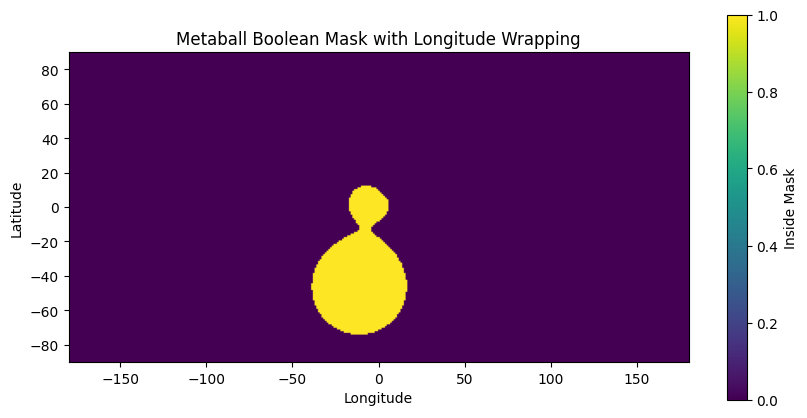

In [36]:

# Example usage
lat_extent = 90
lon_extent = 180
I = 6  # number of metaballs
#samples = 20

lats = np.linspace(-lat_extent, lat_extent, 2 * lat_extent + 1)
lons = np.linspace(-lon_extent, lon_extent, 2 * lon_extent + 1)

# Customizable center and size
center_lat = 0
center_lon = 0
size = 10  # controls spread of effect


#mask = np.zeros((2 * lat_extent + 1, 2 * lon_extent + 1), dtype=bool)
mask = make_shape(
    lats=lats,
    lons=lons,
    center_lat=center_lat,
    center_lon=center_lon,
    size=size,
    I=I,  # number of metaballs
    #goo=1.5,
    #random_seed=2,  # Set to None for random parameters
)

# Plot mask
plt.figure(figsize=(10, 5))
plt.imshow(mask, extent=[-lon_extent, lon_extent, -lat_extent, lat_extent], origin="lower", cmap="viridis")
plt.colorbar(label="Inside Mask")
plt.title("Metaball Boolean Mask with Longitude Wrapping")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()


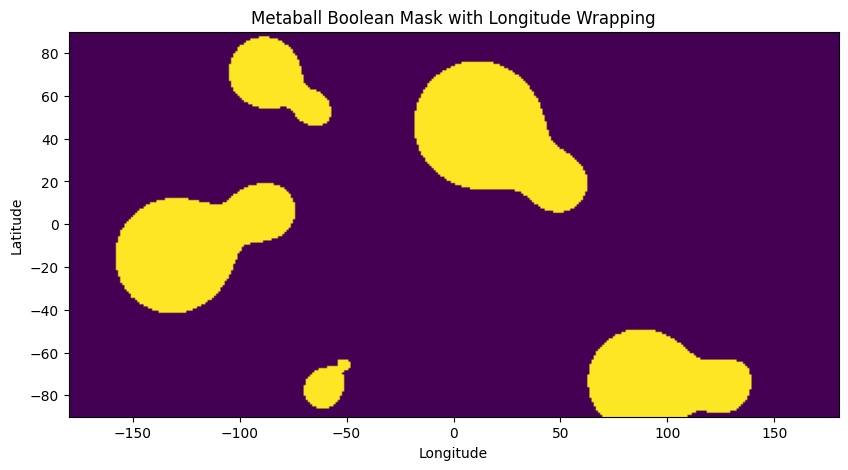

In [37]:
# Example usage
lat_extent = 90
lon_extent = 180
size = lon_extent / 20  # Use lon_extent as radius
I = 5  # number of metaballs
samples = 5

lats = np.linspace(-lat_extent, lat_extent, 2 * lat_extent + 1)
lons = np.linspace(-lon_extent, lon_extent, 2 * lon_extent + 1)

mask_tot = np.zeros((2*lat_extent + 1, 2*lon_extent + 1), dtype=bool)
for _ in range(samples):
    center_lat = np.random.uniform(-lat_extent, lat_extent)
    center_lon = np.random.uniform(-lon_extent, lon_extent)

    # Create a mask
    mask = make_shape(
        lats=lats,
        lons=lons,
        center_lat=center_lat,
        center_lon=center_lon,
        size=size,  # Use lon_extent as radius
        I=I,
        #random_seed=8,
)
    mask_tot |= mask

# Plot mask
plt.figure(figsize=(10, 5))
plt.imshow(mask_tot, extent=[-lon_extent, lon_extent, -lat_extent, lat_extent], origin="lower", cmap="viridis")
plt.title("Metaball Boolean Mask with Longitude Wrapping")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

/home/lukasro/Documents/TIPMIP/ponds/ponds/shiftgen.py:33: UserWarning: No random seed set for PONDS. Results will not be reproducible.
  warnings.warn(


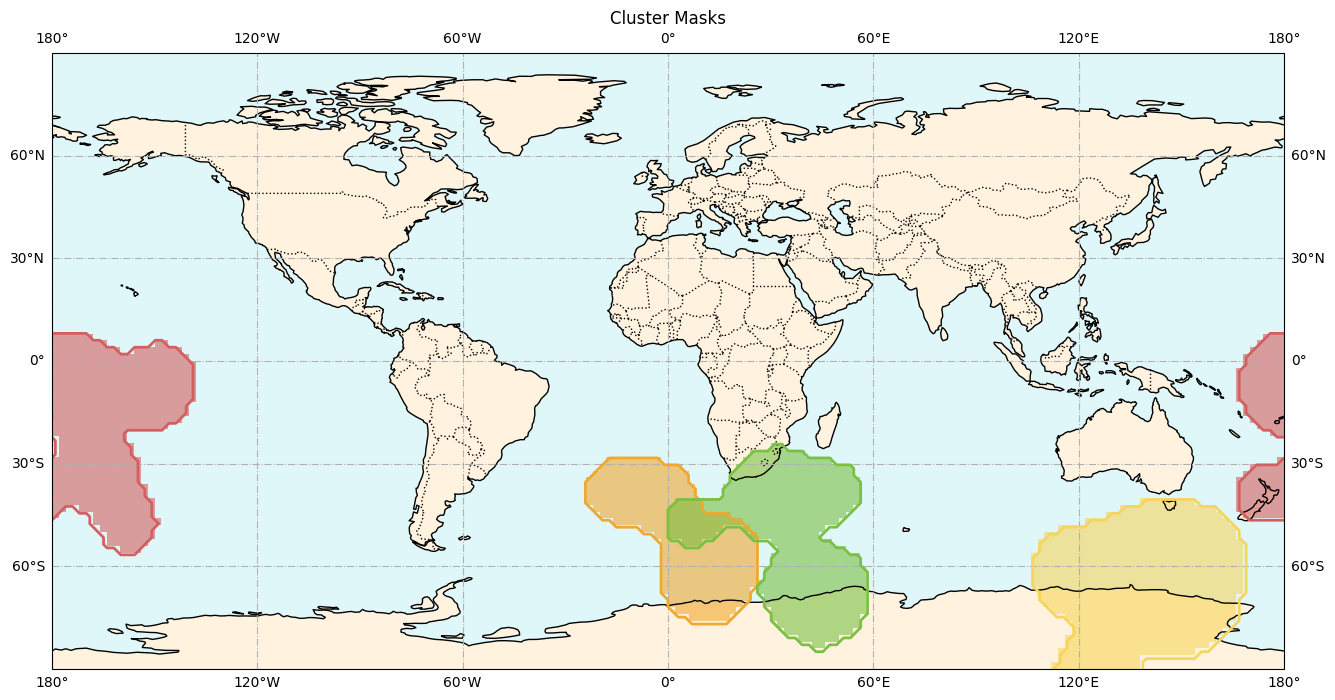

In [18]:
from ponds import PONDS, BLOB, SIGMOID

samples = 4

pd = PONDS(
    lat_size=90,
    lon_size=180,
)

for i in range(samples):
    pd.add_shift(
        shift_method=SIGMOID(),
        shape_method=BLOB(size=5),
    )

pd.worldmap(
    #show_cells=True,
)